# Support Vector Regression with linear and non-linear kernels: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/svm/plot_svm_regression.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/svm/plot_svm_regression.html)).

**Scenario:** 40 sorted points of a noisy sine fitted with `SVR(kernel="rbf", C=100, gamma=0.1, epsilon=0.1)`,
`SVR(kernel="linear", C=100, gamma="auto")` and `SVR(kernel="poly", C=100, gamma="auto", degree=3, epsilon=0.1, coef0=1)`;
the plot marks each model's `support_` rows.

Extra checks beyond the plot: `support_vectors_`, `dual_coef_`, `intercept_`, `n_support_`, `n_iter_`,
`fit_status_`, `coef_` (linear kernel only, and its `AttributeError` for the others), `score` (R2), Float32
input, and the other two regressors of the module on the same data: `NuSVR(C=100, gamma=0.1)` and
`LinearSVR(C=10, epsilon=0.1, random_state=0, max_iter=10000)`.

**Adaptations:**
- The example draws its data from NumPy's global stream without a seed. The notebook calls
  `np.random.seed(0)` first, so the data (and therefore both sides) are reproducible; the data are then shared.
- `coef_` is the method `coef_()` in Moxie; `n_iter_` is an `Int` for regressors, as in sklearn.
- Figures are smaller (dpi 80); Moxie's fitted curves and support vectors are drawn in a paired figure.

**Determinism:** deterministic after seeding. SVR consumes no random numbers. `LinearSVR`'s dual coordinate
descent shuffles with `random_state=0`, which Moxie reproduces through its port of LIBLINEAR's RNG.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("svm/plot_svm_regression")

## 1. scikit-learn (Python reference)

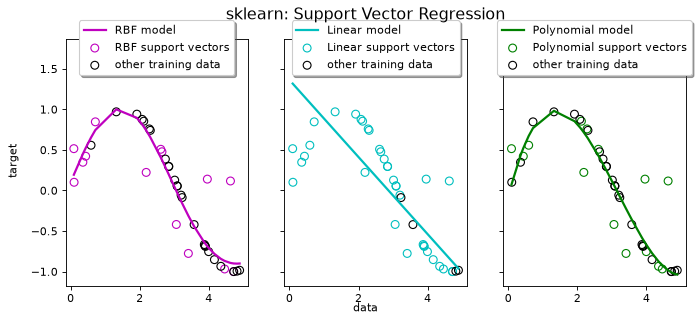

rbf n_support_ [15] n_iter_ 1717 R2 0.756629
linear n_support_ [36] n_iter_ 33456 R2 0.461265
poly n_support_ [15] n_iter_ 14925202 R2 0.747611
rbf coef_: coef_ is only available when using a linear kernel
poly coef_: coef_ is only available when using a linear kernel


In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.svm import SVR

np.random.seed(0)  # adaptation: the example is unseeded
X = np.sort(5 * np.random.rand(40, 1), axis=0)
y = np.sin(X).ravel()

y[::5] += 3 * (0.5 - np.random.rand(8))

svr_rbf = SVR(kernel="rbf", C=100, gamma=0.1, epsilon=0.1)
svr_lin = SVR(kernel="linear", C=100, gamma="auto")
svr_poly = SVR(kernel="poly", C=100, gamma="auto", degree=3, epsilon=0.1, coef0=1)

lw = 2

svrs = [svr_rbf, svr_lin, svr_poly]
kernel_label = ["RBF", "Linear", "Polynomial"]
model_color = ["m", "c", "g"]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10, 4), sharey=True, dpi=80)
sk_pred = []
for ix, svr in enumerate(svrs):
    sk_pred.append(svr.fit(X, y).predict(X))
    axes[ix].plot(X, sk_pred[-1], color=model_color[ix], lw=lw,
                  label="{} model".format(kernel_label[ix]))
    axes[ix].scatter(X[svr.support_], y[svr.support_], facecolor="none",
                     edgecolor=model_color[ix], s=50,
                     label="{} support vectors".format(kernel_label[ix]))
    axes[ix].scatter(X[np.setdiff1d(np.arange(len(X)), svr.support_)],
                     y[np.setdiff1d(np.arange(len(X)), svr.support_)],
                     facecolor="none", edgecolor="k", s=50, label="other training data")
    axes[ix].legend(loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=1, fancybox=True, shadow=True)

fig.text(0.5, 0.04, "data", ha="center", va="center")
fig.text(0.06, 0.5, "target", ha="center", va="center", rotation="vertical")
fig.suptitle("sklearn: Support Vector Regression", fontsize=14)
plt.show()

from sklearn.svm import NuSVR, LinearSVR
nusvr = NuSVR(C=100, gamma=0.1).fit(X, y)
linsvr = LinearSVR(C=10, epsilon=0.1, random_state=0, max_iter=10000).fit(X, y)
svr32 = SVR(kernel="rbf", C=100, gamma=0.1, epsilon=0.1).fit(X.astype(np.float32), y)
X_query = np.linspace(-0.5, 5.5, 61)[:, None]
for svr in svrs:
    print(svr.kernel, "n_support_", svr.n_support_, "n_iter_", svr.n_iter_, "R2", round(svr.score(X, y), 6))
for svr in (svr_rbf, svr_poly):
    try:
        svr.coef_
    except AttributeError as exc:
        print(svr.kernel, "coef_:", exc)
nb.share(X=X, y=y, X32=X.astype(np.float32), X_query=X_query)

## 2. Moxie (native Mojo)

In [3]:
%%mojo svr
import numojo as nm
from moxie.svm import SVR, NuSVR, LinearSVR
from moxie_nb_io import load, save, save_ints, save_floats


def record(name: String, svr: SVR, X: nm.NDArray[DType.float64], y: nm.NDArray[DType.float64], q: nm.NDArray[DType.float64]) raises:
    save(name + "_pred", svr.predict(X))
    save(name + "_query", svr.predict(q))
    save(name + "_support", svr.support_)
    save(name + "_support_vectors", svr.support_vectors_)
    save(name + "_dual_coef", svr.dual_coef_)
    save(name + "_intercept", svr.intercept_)
    save(name + "_n_support", svr.n_support_)
    save_ints(name + "_meta", [svr.n_iter_, svr.fit_status_, svr.n_features_in_])
    save_floats(name + "_score", [svr.score(X, y)])


def main() raises:
    var X = load("X")
    var y = load("y")
    var q = load("X_query")
    var svr_rbf = SVR(kernel="rbf", C=100, gamma=0.1, epsilon=0.1)
    var svr_lin = SVR(kernel="linear", C=100, gamma="auto")
    var svr_poly = SVR(kernel="poly", C=100, gamma="auto", degree=3, epsilon=0.1, coef0=1)
    _ = svr_rbf.fit(X, y)
    _ = svr_lin.fit(X, y)
    _ = svr_poly.fit(X, y)
    record("rbf", svr_rbf, X, y, q)
    record("linear", svr_lin, X, y, q)
    record("poly", svr_poly, X, y, q)
    save("linear_coef", svr_lin.coef_())
    try:
        _ = svr_rbf.coef_()
    except e:
        print("rbf coef_:", e)
    try:
        _ = svr_poly.coef_()
    except e:
        print("poly coef_:", e)
    var svr32 = SVR(kernel="rbf", C=100, gamma=0.1, epsilon=0.1)
    _ = svr32.fit(load[DType.float32]("X32"), y)
    save("rbf32_query", svr32.predict(q))
    var nusvr = NuSVR(C=100, gamma=0.1)
    _ = nusvr.fit(X, y)
    save("nu_query", nusvr.predict(q))
    save("nu_support", nusvr.support_)
    save("nu_dual_coef", nusvr.dual_coef_)
    save("nu_intercept", nusvr.intercept_)
    var linsvr = LinearSVR(C=10, epsilon=0.1, random_state=0, max_iter=10000)
    _ = linsvr.fit(X, y)
    save("lin_coef", linsvr.coef_)
    save("lin_intercept", linsvr.intercept_)
    save("lin_query", linsvr.predict(q))
    save_ints("lin_n_iter", [linsvr.n_iter_])

rbf coef_: AttributeError: coef_ is only available when using a linear kernel
poly coef_: AttributeError: coef_ is only available when using a linear kernel


## 3. Side by side and parity

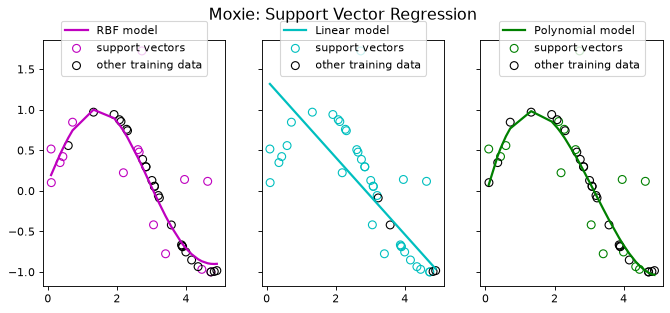

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
rbf: predict(X),PASS,"(40,)","(40,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so the converged duals differ by rounding (family parity bound rtol 3e-5 / atol 3e-6)"
rbf: predict(query),PASS,"(61,)","(61,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so the converged duals differ by rounding (family parity bound rtol 3e-5 / atol 3e-6)"
rbf: support_,PASS,"(15,)","(15,)",,,exact,0 mismatches,
rbf: support_vectors_,PASS,"(15, 1)","(15, 1)",,,exact,0 mismatches,
rbf: n_support_,PASS,"(1,)","(1,)",,,exact,0 mismatches,
rbf: dual_coef_,PASS,"(1, 15)","(1, 15)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so the converged duals differ by rounding (family parity bound rtol 3e-5 / atol 3e-6)"
rbf: intercept_,PASS,"(1,)","(1,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so the converged duals differ by rounding (family parity bound rtol 3e-5 / atol 3e-6)"
"rbf: n_iter_, fit_status_, n_features_in_",PASS,"(3,)","(3,)",,,exact,0 mismatches,
rbf: score (R2),PASS,"(1,)","(1,)",1.11e-16,1.47e-16,"rtol=1e-09, atol=0",,R2 of predictions that agree to the solver bound above
linear: predict(X),PASS,"(40,)","(40,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so the converged duals differ by rounding (family parity bound rtol 3e-5 / atol 3e-6)"


In [4]:
mx = nb.results["svr"]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10, 4), sharey=True, dpi=80)
for ix, name in enumerate(["rbf", "linear", "poly"]):
    sup = mx[f"{name}_support"]
    axes[ix].plot(X, mx[f"{name}_pred"], color=model_color[ix], lw=lw, label=f"{kernel_label[ix]} model")
    axes[ix].scatter(X[sup], y[sup], facecolor="none", edgecolor=model_color[ix], s=50, label="support vectors")
    rest = np.setdiff1d(np.arange(len(X)), sup)
    axes[ix].scatter(X[rest], y[rest], facecolor="none", edgecolor="k", s=50, label="other training data")
    axes[ix].legend(loc="upper center", bbox_to_anchor=(0.5, 1.1))
fig.suptitle("Moxie: Support Vector Regression", fontsize=14)
plt.show()

moxie_nb.side_by_side(sklearn_n_support=[s.n_support_[0] for s in svrs],
                      moxie_n_support=[mx[f"{n}_n_support"][0] for n in ("rbf", "linear", "poly")],
                      sklearn_R2=[s.score(X, y) for s in svrs],
                      moxie_R2=[mx[f"{n}_score"][0] for n in ("rbf", "linear", "poly")])

SOLVER = ("same LIBSVM epsilon-SVR SMO in Float64, tol=1e-3; kernel sums and gradient updates use a "
          "different summation order, so the converged duals differ by rounding (family parity bound "
          "rtol 3e-5 / atol 3e-6)")
for svr, name in zip(svrs, ["rbf", "linear", "poly"]):
    nb.compare(f"{name}: predict(X)", svr.predict(X), mx[f"{name}_pred"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"{name}: predict(query)", svr.predict(X_query), mx[f"{name}_query"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"{name}: support_", svr.support_, mx[f"{name}_support"], exact=True)
    nb.compare(f"{name}: support_vectors_", svr.support_vectors_, mx[f"{name}_support_vectors"], exact=True)
    nb.compare(f"{name}: n_support_", svr.n_support_, mx[f"{name}_n_support"], exact=True)
    nb.compare(f"{name}: dual_coef_", svr.dual_coef_, mx[f"{name}_dual_coef"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"{name}: intercept_", svr.intercept_, mx[f"{name}_intercept"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"{name}: n_iter_, fit_status_, n_features_in_",
               [svr.n_iter_, svr.fit_status_, svr.n_features_in_], mx[f"{name}_meta"], exact=True)
    nb.compare(f"{name}: score (R2)", [svr.score(X, y)], mx[f"{name}_score"], rtol=1e-9,
               reason="R2 of predictions that agree to the solver bound above")
nb.compare("linear: coef_", svr_lin.coef_, mx["linear_coef"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.note("rbf/poly coef_", "PASS", "both raise AttributeError for nonlinear kernels (printed above)")
nb.compare("rbf on Float32 X: predict(query)", svr32.predict(X_query), mx["rbf32_query"], rtol=3e-5, atol=3e-6,
           reason="both widen Float32 to Float64 before fitting; " + SOLVER)
nb.compare("NuSVR: predict(query)", nusvr.predict(X_query), mx["nu_query"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("NuSVR: support_", nusvr.support_, mx["nu_support"], exact=True)
nb.compare("NuSVR: dual_coef_", nusvr.dual_coef_, mx["nu_dual_coef"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("NuSVR: intercept_", nusvr.intercept_, mx["nu_intercept"], rtol=3e-5, atol=3e-6, reason=SOLVER)
LIN = ("LIBLINEAR dual coordinate descent with the same seeded permutation stream; dot products are "
       "accumulated in a different order (family linear parity bound rtol 5e-5 / atol 3e-6)")
nb.compare("LinearSVR: coef_", linsvr.coef_, mx["lin_coef"], rtol=5e-5, atol=3e-6, reason=LIN)
nb.compare("LinearSVR: intercept_", linsvr.intercept_, mx["lin_intercept"], rtol=5e-5, atol=3e-6, reason=LIN)
nb.compare("LinearSVR: predict(query)", linsvr.predict(X_query), mx["lin_query"], rtol=7e-5, atol=2e-5, reason=LIN)
nb.compare("LinearSVR: n_iter_", [linsvr.n_iter_], mx["lin_n_iter"], exact=True)
nb.report()
nb.assert_parity()